PRACTICAL 6: CLUSTERING ALGORITHMS

STEP 1: Upload Mall_Customers.csv
Select your CSV file in the file picker.


Saving Mall_Customers (1).csv to Mall_Customers (1).csv

Dataset uploaded successfully!
Filename: Mall_Customers (1).csv
Dataset shape: (200, 5)

First five records:
 CustomerID Gender  Age  Annual Income (k$)  Spending Score (1-100)
          1   Male   19                  15                      39
          2   Male   21                  15                      81
          3 Female   20                  16                       6
          4 Female   23                  16                      77
          5 Female   31                  17                      40

STEP 2: CHECK DATASET
Columns: ['CustomerID', 'Gender', 'Age', 'annual_income', 'spending_score']

Missing values:
CustomerID        0
Gender            0
Age               0
annual_income     0
spending_score    0
dtype: int64

STEP 3: DATA PREPROCESSING
Features selected: ['annual_income', 'spending_score']
Valid records: 200
Missing values handled.
Feature scaling completed.

STEP 4: ELBOW METHOD


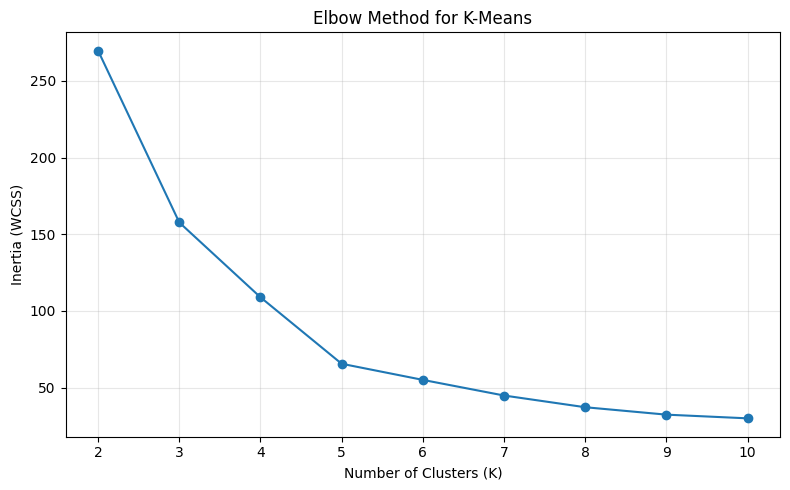

Elbow graph generated.

STEP 5: MODEL COMPARISON

Performance of all tested configurations:
    Algorithm  Clusters  Silhouette Score  Davies-Bouldin Index  Calinski-Harabasz Score
      K-Means         2            0.3213                1.2670                  95.6694
Agglomerative         2            0.3842                0.8544                  86.9616
      K-Means         3            0.4666                0.7165                 151.3351
Agglomerative         3            0.4610                0.7073                 143.7796
      K-Means         4            0.4939                0.7096                 174.5952
Agglomerative         4            0.4926                0.6707                 169.6798
      K-Means         5            0.5547                0.5722                 248.6493
Agglomerative         5            0.5538                0.5779                 244.4103
      K-Means         6            0.5399                0.6546                 243.0879
Agglomerative     

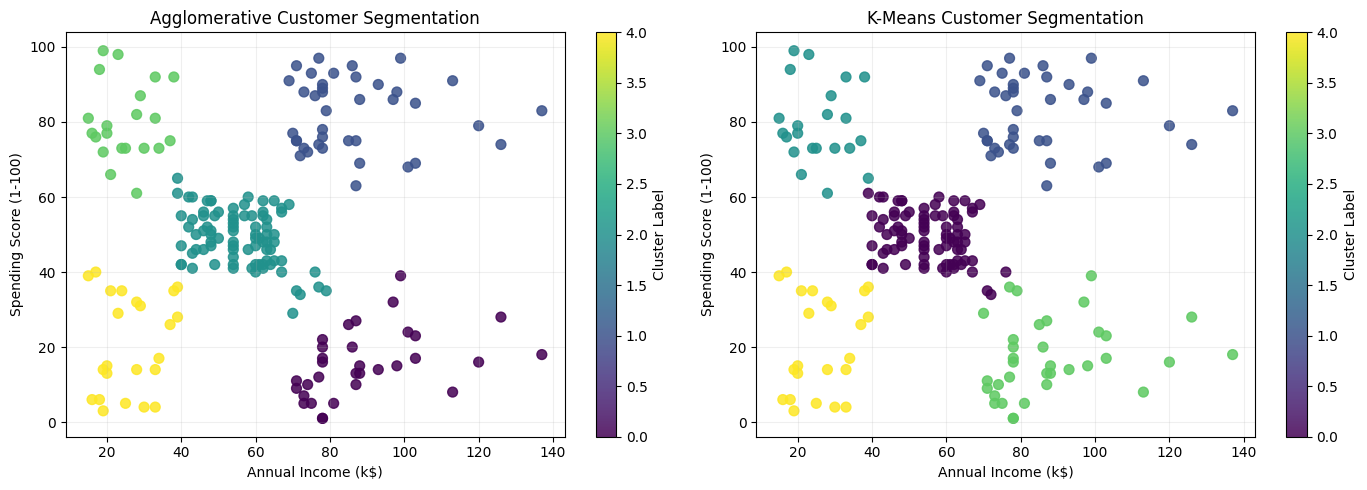


STEP 8: FINAL PERFORMANCE EVALUATION

Algorithm: Agglomerative
Number of clusters: 5
Silhouette Score: 0.5538
Davies-Bouldin Index: 0.5779
Calinski-Harabasz Score: 244.4103

Number of customers in each cluster:
0    32
1    39
2    85
3    21
4    23

Algorithm: K-Means
Number of clusters: 5
Silhouette Score: 0.5547
Davies-Bouldin Index: 0.5722
Calinski-Harabasz Score: 248.6493

Number of customers in each cluster:
0    81
1    39
2    22
3    35
4    23

STEP 9: CUSTOMER CLUSTER PROFILES

 Agglomerative Cluster Profiles:
         Customer_Count  Average_Annual_Income  Average_Spending_Score
Cluster                                                               
0                    32                  89.41                   15.59
1                    39                  86.54                   82.13
2                    85                  55.81                   49.13
3                    21                  25.10                   80.05
4                    23                  26.3

In [1]:

# ================================================================
# PRACTICAL 6: CLUSTERING ALGORITHMS
# Customer Segmentation using K-Means and Agglomerative Clustering
# ================================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import io

from google.colab import files
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

print("=" * 70)
print("PRACTICAL 6: CLUSTERING ALGORITHMS")
print("=" * 70)

# STEP 1: UPLOAD CSV DATASET
print("\nSTEP 1: Upload Mall_Customers.csv")
print("Select your CSV file in the file picker.")

uploaded = files.upload()

if not uploaded:
    raise ValueError("No file uploaded. Please select a CSV file.")

filename = next(iter(uploaded))
df = pd.read_csv(io.BytesIO(uploaded[filename]))

print("\nDataset uploaded successfully!")
print("Filename:", filename)
print("Dataset shape:", df.shape)
print("\nFirst five records:")
print(df.head().to_string(index=False))

# STEP 2: PREPARE COLUMN NAMES
print("\nSTEP 2: CHECK DATASET")

column_map = {}

for col in df.columns:
    normalized = (
        str(col).strip().lower()
        .replace(" ", "_")
        .replace("(", "")
        .replace(")", "")
    )

    if "annual" in normalized and "income" in normalized:
        column_map[col] = "annual_income"
    elif "spending" in normalized and "score" in normalized:
        column_map[col] = "spending_score"

df.rename(columns=column_map, inplace=True)

required_columns = ["annual_income", "spending_score"]

if not all(col in df.columns for col in required_columns):
    raise ValueError(
        "The CSV must contain Annual Income and Spending Score columns. "
        "Available columns: " + str(df.columns.tolist())
    )

print("Columns:", df.columns.tolist())
print("\nMissing values:")
print(df.isnull().sum())

# STEP 3: DATA PREPROCESSING
print("\nSTEP 3: DATA PREPROCESSING")

X = df[["annual_income", "spending_score"]].copy()

for col in X.columns:
    X[col] = pd.to_numeric(X[col], errors="coerce")

X = X.replace([np.inf, -np.inf], np.nan)
X = X.fillna(X.median())
X = X.dropna()

if len(X) < 3:
    raise ValueError("At least three valid customer records are required.")

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Features selected:", list(X.columns))
print("Valid records:", len(X))
print("Missing values handled.")
print("Feature scaling completed.")

# STEP 4: ELBOW METHOD
print("\nSTEP 4: ELBOW METHOD")

k_values = list(range(2, min(11, len(X))))
inertias = []

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    model.fit(X_scaled)
    inertias.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(k_values, inertias, marker="o")
plt.title("Elbow Method for K-Means")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia (WCSS)")
plt.xticks(k_values)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("Elbow graph generated.")

# STEP 5: TRAIN AND COMPARE CLUSTERING MODELS
print("\nSTEP 5: MODEL COMPARISON")

results = []

for k in k_values:
    models = {
        "K-Means": KMeans(
            n_clusters=k,
            random_state=42,
            n_init=10
        ),
        "Agglomerative": AgglomerativeClustering(
            n_clusters=k,
            linkage="ward"
        )
    }

    for name, model in models.items():
        labels = model.fit_predict(X_scaled)

        results.append({
            "Algorithm": name,
            "Clusters": k,
            "Silhouette Score": silhouette_score(
                X_scaled, labels
            ),
            "Davies-Bouldin Index": davies_bouldin_score(
                X_scaled, labels
            ),
            "Calinski-Harabasz Score": calinski_harabasz_score(
                X_scaled, labels
            )
        })

results_df = pd.DataFrame(results)

print("\nPerformance of all tested configurations:")
print(results_df.round(4).to_string(index=False))

# STEP 6: SELECT CONFIGURATION WITH HIGHEST SILHOUETTE SCORE
print("\nSTEP 6: SELECTED MODELS")

best_indices = results_df.groupby(
    "Algorithm"
)["Silhouette Score"].idxmax()

best_results = (
    results_df.loc[best_indices]
    .sort_values("Algorithm")
    .reset_index(drop=True)
)

print(best_results.round(4).to_string(index=False))

# STEP 7: VISUALIZE CUSTOMER SEGMENTS
print("\nSTEP 7: CLUSTER VISUALIZATION")

final_models = {}

for _, row in best_results.iterrows():
    name = row["Algorithm"]
    k = int(row["Clusters"])

    if name == "K-Means":
        model = KMeans(
            n_clusters=k,
            random_state=42,
            n_init=10
        )
    else:
        model = AgglomerativeClustering(
            n_clusters=k,
            linkage="ward"
        )

    final_models[name] = model

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, (name, model) in zip(axes, final_models.items()):
    labels = model.fit_predict(X_scaled)

    scatter = ax.scatter(
        X["annual_income"],
        X["spending_score"],
        c=labels,
        cmap="viridis",
        s=50,
        alpha=0.85
    )

    ax.set_title(name + " Customer Segmentation")
    ax.set_xlabel("Annual Income (k$)")
    ax.set_ylabel("Spending Score (1-100)")
    ax.grid(True, alpha=0.2)

    fig.colorbar(scatter, ax=ax, label="Cluster Label")

plt.tight_layout()
plt.show()

# STEP 8: FINAL PERFORMANCE EVALUATION
print("\nSTEP 8: FINAL PERFORMANCE EVALUATION")

final_summary = []

for name, model in final_models.items():
    labels = model.fit_predict(X_scaled)

    silhouette = silhouette_score(X_scaled, labels)
    db_index = davies_bouldin_score(X_scaled, labels)
    ch_score = calinski_harabasz_score(X_scaled, labels)

    print("\nAlgorithm:", name)
    print("Number of clusters:", len(np.unique(labels)))
    print("Silhouette Score:", round(silhouette, 4))
    print("Davies-Bouldin Index:", round(db_index, 4))
    print("Calinski-Harabasz Score:", round(ch_score, 4))

    print("\nNumber of customers in each cluster:")
    print(
        pd.Series(labels)
        .value_counts()
        .sort_index()
        .to_string()
    )

    final_summary.append({
        "Algorithm": name,
        "Clusters": len(np.unique(labels)),
        "Silhouette Score": silhouette,
        "Davies-Bouldin Index": db_index,
        "Calinski-Harabasz Score": ch_score
    })

# STEP 9: CUSTOMER CLUSTER PROFILES
print("\nSTEP 9: CUSTOMER CLUSTER PROFILES")

for name, model in final_models.items():
    labels = model.fit_predict(X_scaled)

    profile = X.copy()
    profile["Cluster"] = labels

    cluster_profile = profile.groupby("Cluster").agg(
        Customer_Count=("annual_income", "size"),
        Average_Annual_Income=("annual_income", "mean"),
        Average_Spending_Score=("spending_score", "mean")
    ).round(2)

    print("\n", name, "Cluster Profiles:")
    print(cluster_profile.to_string())

# STEP 10: FINAL COMPARISON
print("\nSTEP 10: FINAL COMPARISON TABLE")

summary_df = pd.DataFrame(final_summary)
print(summary_df.round(4).to_string(index=False))

print("\nMETRIC INTERPRETATION")
print("1. Higher Silhouette Score is generally better.")
print("2. Lower Davies-Bouldin Index is generally better.")
print("3. Higher Calinski-Harabasz Score is generally better.")
print("4. Consider all metrics and cluster plots together.")
print("5. The highest silhouette score is the selection rule used here.")

print("\nCOMPLETED SUCCESSFULLY!")
